# One coupled system: recover, simulate, fit and check

Can a two-reservoir tracer model explain a changing observation while preserving what should stay constant?

Proposed 2027; calendar dates pending.


# One system, three operations
Predict total mass, the initial transfer direction and equilibrium before execution. All quantities are synthetic.

In [1]:
import numpy as np
from demo import SENSOR, INITIAL, recover_initial, exact, simulate, euler, fit_rate, run
reading = SENSOR @ INITIAL
recovered, residual = recover_initial(reading)
print("Readings (mg-equivalent):", reading)
print("Recovered masses (mg):", recovered, "residual:", residual)

Readings (mg-equivalent): [8.4 2.8]
Recovered masses (mg): [8. 2.] residual: 0.0


Required implementation: write one transfer expression and reuse it with opposite signs. The example below is a guided baseline; change k and predict the initial slope before rerunning.

In [2]:
def exchange_rhs(time_min, state_mg, k_per_min):
    transfer_mg_per_min = k_per_min * (state_mg[0] - state_mg[1])
    return np.array([-transfer_mg_per_min, transfer_mg_per_min])
rate = exchange_rhs(0, INITIAL, 0.3)
print("Initial rates (mg/min):", rate)
assert abs(rate.sum()) < 1e-12
print("One half-minute Euler step (mg):", INITIAL + 0.5 * rate)

Initial rates (mg/min): [-1.8  1.8]
One half-minute Euler step (mg): [7.1 2.9]


Run the derivative you just defined through the library solver, then compare to the exact baseline. Requested output times are not a declaration of internal step size.

In [3]:
from scipy.integrate import solve_ivp
times = np.linspace(0, 6, 61)
solution = solve_ivp(lambda t, m: exchange_rhs(t, m, 0.3), (0, 6), INITIAL, t_eval=times, rtol=1e-8, atol=1e-10)
assert solution.success
states = solution.y.T
print("Max total-mass discrepancy (mg):", np.max(abs(states.sum(axis=1) - 10)))
print("Max exact-solution error (mg):", np.max(abs(states - exact(times))))

Max total-mass discrepancy (mg): 1.7763568394002505e-15
Max exact-solution error (mg): 8.73541505796993e-09


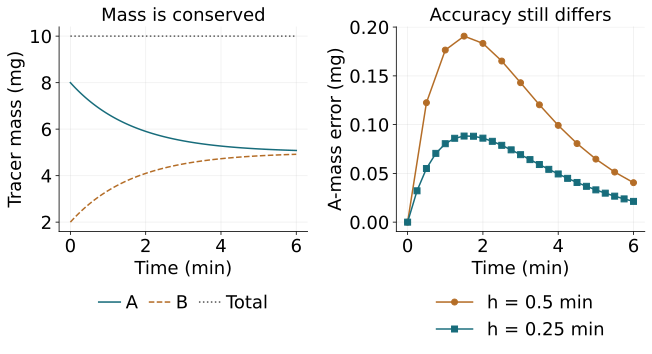

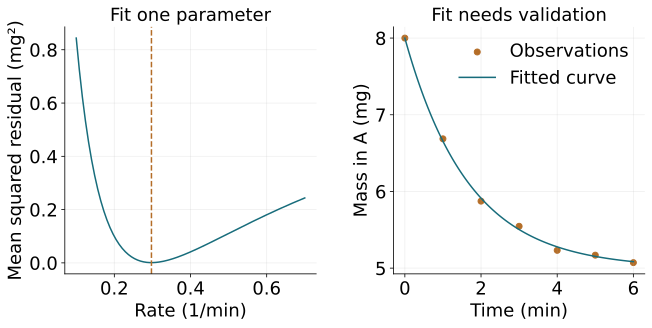

In [4]:
from IPython.display import SVG, display
report = run()
display(SVG(filename="exchange-and-error.svg"))
display(SVG(filename="parameter-evidence.svg"))

Predict the zero-rate limit, then test it. Build a new guided synthetic observation set with a declared rate and a small perturbation; the fit should be interpreted as a model-conditioned estimate.

In [5]:
assert np.allclose(simulate([0, 1, 2], k=0), np.tile(INITIAL, (3, 1)))
observation_times = np.arange(7.)
true_rate = 0.4
observed_A = exact(observation_times, true_rate)[:, 0] + np.array([0, .02, -.02, .01, -.01, .02, 0])
fitted = fit_rate(observation_times, observed_A)
print(fitted)

{'rate_per_min': 0.3986658545014391, 'mean_squared_residual_mg2': 0.00019560517163510327, 'bounds_per_min': [0.01, 1.0]}


Display this changed fit. Interpret the difference from the baseline and state why the fitting residual cannot validate the closed-system assumption.

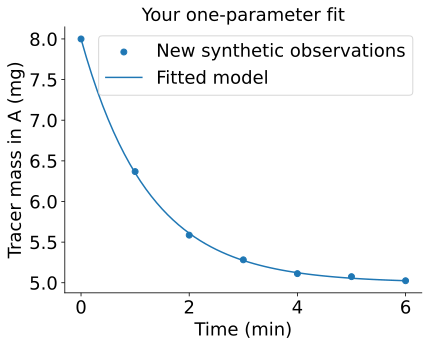

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.scatter(observation_times, observed_A, label="New synthetic observations")
ax.plot(times, exact(times, fitted["rate_per_min"])[:, 0], label="Fitted model")
ax.set(xlabel="Time (min)", ylabel="Tracer mass in A (mg)", title="Your one-parameter fit")
ax.legend()
fig.savefig("edited-fit.svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename="edited-fit.svg"))

Restart and run all cells. Separate a linear residual, an integration error and a fitting residual in your explanation. Optional extension: derive the full Euler stability interval; it is broader than the monotonicity guard used here.